# Ekip Verimliliği Tahmini

Amaç, üretim özellikleriyle ekiplerin gerçekleşen verimliliğini tahmin etmek ve tahmine en çok katkı sağlayan değişkenleri belirlemek. Veri `data_preparation.ipynb` ile hazırlanan temiz CSV’den geliyor.

In [2]:
from pathlib import Path

import joblib

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import ExtraTreesRegressor, GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

In [3]:
df = pd.read_csv("./data/processed/garments_worker_productivity_clean.csv")

categorical_columns = ["department", "day", "team"]
numeric_columns = [
    "targeted_productivity", "over_time", "incentive", "no_of_workers",
    "smv", "no_of_style_change",
]
feature_columns = categorical_columns + numeric_columns
X = df[feature_columns]
y = df["actual_productivity"]

Hedeflenen verimlilik, fazla mesai, prim ve çalışan sayısı gibi üretim bilgileri model girdisi olarak kullanıldı. Model, bu bilgiler eldeyken verimliliği tahmin eder.

## Eğitim ve test ayrımı

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Eğitim: {len(X_train)} kayıt")
print(f"Test: {len(X_test)} kayıt")

Eğitim: 957 kayıt
Test: 240 kayıt


Kayıtların %80’i rastgele eğitim, %20’si test için ayrıldı. `random_state=42` ayrımı tekrarlanabilir kılıyor.

## Model karşılaştırması

In [5]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Medyan": DummyRegressor(strategy="median"),
    "Doğrusal regresyon": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42,
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, max_depth=8, min_samples_leaf=5, random_state=42,
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

pipelines = {}
results = []
for name, model in models.items():
    preprocess = ColumnTransformer(
        [("categories", OneHotEncoder(handle_unknown="ignore"), categorical_columns)],
        remainder="passthrough",
    )
    pipeline = Pipeline([
        ("preprocess", preprocess),
        ("regressor", model),
    ])
    pipelines[name] = pipeline
    scores = -cross_val_score(
        pipeline, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error",
    )
    results.append({"Model": name, "CV MAE (puan)": scores.mean() * 100})

comparison = pd.DataFrame(results).sort_values("CV MAE (puan)").reset_index(drop=True)
comparison.round(2)

,Model,CV MAE (puan)
0,Random Forest,8.26
1,Gradient Boosting,8.51
2,Extra Trees,9.07
3,Doğrusal regresyon,10.97
4,Ridge,11.10
5,Medyan,13.50


Random Forest (8,26 puan) ve Gradient Boosting (8,51 puan) ilk karşılaştırmada en düşük ortalama MAE’yi verdi. Tüm modeller aynı beş katlı çapraz doğrulamayla değerlendirildi.

## Random Forest parametre araması

Random Forest ilk karşılaştırmada en düşük MAE’yi verdi. Aralıkları önceki 100 ağaç ve 8 derinlik ayarını içerecek şekilde seçtim. Arama yalnızca eğitim verisinde yapıldı.

In [6]:
param_grid = {
    "regressor__n_estimators": [100, 200],
    "regressor__max_depth": [5, 8, 12],
    "regressor__min_samples_split": [2, 12],
    "regressor__min_samples_leaf": [2, 5],
    "regressor__max_features": [0.7, 1.0],
}

grid_search = GridSearchCV(
    estimator=pipelines["Random Forest"],
    param_grid=param_grid,
    cv=cv,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
grid_search.fit(X_train, y_train)

print(f"Denenen kombinasyon: {len(grid_search.cv_results_['params'])}")
print(f"En iyi CV MAE: {-grid_search.best_score_ * 100:.2f} puan")
for parameter, value in grid_search.best_params_.items():
    print(f"{parameter}: {value}")

Denenen kombinasyon: 48
En iyi CV MAE: 7.99 puan
regressor__max_depth: 12
regressor__max_features: 0.7
regressor__min_samples_leaf: 2
regressor__min_samples_split: 2
regressor__n_estimators: 200


## Test sonuçları

In [7]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

print(f"Eğitim MAE: {mean_absolute_error(y_train, best_model.predict(X_train)) * 100:.2f} puan")
print(f"Test MAE: {mean_absolute_error(y_test, y_pred) * 100:.2f} puan")
print(f"Test RMSE: {root_mean_squared_error(y_test, y_pred) * 100:.2f} puan")
print(f"Test R²: {r2_score(y_test, y_pred):.2f}")

baseline = pipelines["Random Forest"].fit(X_train, y_train)
baseline_mae = mean_absolute_error(y_test, baseline.predict(X_test)) * 100
print(f"Önceki Random Forest ayarının test MAE’si: {baseline_mae:.2f} puan")

Eğitim MAE: 4.86 puan
Test MAE: 6.99 puan
Test RMSE: 11.20 puan
Test R²: 0.53
Önceki Random Forest ayarının test MAE’si: 7.30 puan


Random Forest’ın doğrulama MAE’si 8,26 puandan 7,99 puana, test MAE’si 7,30 puandan 6,99 puana değişti.

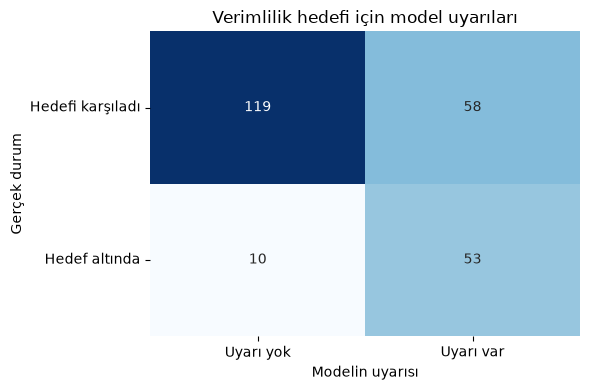

In [8]:
goal = X_test["targeted_productivity"]
missed_target = y_test.lt(goal)
warning = pd.Series(y_pred, index=y_test.index).lt(goal)

warning_matrix = pd.crosstab(missed_target, warning).reindex(
    index=[False, True], columns=[False, True], fill_value=0,
)
warning_matrix.index = ["Hedefi karşıladı", "Hedef altında"]
warning_matrix.columns = ["Uyarı yok", "Uyarı var"]

fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(warning_matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(
    title="Verimlilik hedefi için model uyarıları",
    xlabel="Modelin uyarısı",
    ylabel="Gerçek durum",
)
ax.tick_params(axis="y", labelrotation=0)
fig.tight_layout()
plt.show()

Model, hedefi kaçıran 63 kaydın 53 tanesini belirledi. Hedefi karşılayan 58 kayıt için de uyarı verdi.

## Değişken önemi

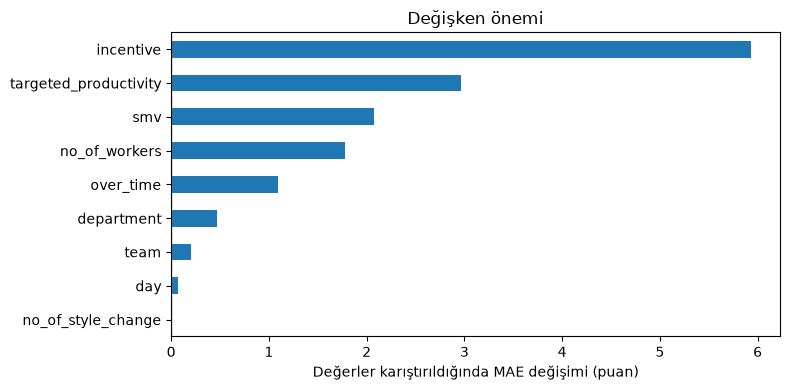

In [9]:
importance = permutation_importance(
    best_model, X_test, y_test, scoring="neg_mean_absolute_error",
    n_repeats=10, random_state=42,
)
importance_scores = pd.Series(
    importance.importances_mean * 100, index=feature_columns,
).sort_values()

ax = importance_scores.plot.barh(figsize=(8, 4))
ax.axvline(0, color="gray", linewidth=1)
ax.set(title="Değişken önemi", xlabel="Değerler karıştırıldığında MAE değişimi (puan)")
plt.tight_layout()
plt.show()

En çok katkı sağlayan girdiler `incentive`, `targeted_productivity`, `smv`. Bu sütunların değerleri karıştırıldığında test hatası en çok arttı. Sonuçlar, yaklaşık iki aylık veriden ayrılan test kayıtlarını kapsıyor.

## SHAP ile model açıklaması

Random Forest’ı 240 test kaydı üzerinde açıkladık. One-Hot Encoding ile oluşan sütunların işaretli katkılarını özgün kategori başlığında topladık. SHAP katkıları verimlilik puanı cinsindendir.

In [10]:
import numpy as np
import shap

preprocess = best_model.named_steps["preprocess"]
regressor = best_model.named_steps["regressor"]
encoded = preprocess.transform(X_test)
if hasattr(encoded, "toarray"):
    encoded = encoded.toarray()

explainer = shap.TreeExplainer(regressor)
encoded_shap = explainer(encoded)
encoder = preprocess.named_transformers_["categories"]
category_ends = np.cumsum([len(levels) for levels in encoder.categories_])
category_starts = np.r_[0, category_ends[:-1]]
category_shap = [
    encoded_shap.values[:, start:end].sum(axis=1)
    for start, end in zip(category_starts, category_ends)
]
contributions = np.column_stack([
    *category_shap, encoded_shap.values[:, category_ends[-1]:],
])

feature_labels = [
    "Bölüm", "Gün", "Ekip", "Hedeflenen verimlilik", "Fazla mesai",
    "Prim", "Çalışan sayısı", "Standart işlem süresi", "Model değişimi sayısı",
]
shap_values = shap.Explanation(
    values=contributions * 100,
    base_values=np.asarray(encoded_shap.base_values).reshape(-1) * 100,
    data=X_test.to_numpy(),
    feature_names=feature_labels,
)

test_rows = df.loc[X_test.index]
example_position = np.flatnonzero(
    pd.to_datetime(test_rows["date"]).eq(pd.Timestamp("2015-02-24"))
    & test_rows["department"].eq("sewing") & test_rows["team"].eq(1)
)[0]
example_shap = shap_values[example_position]
example_actual = y_test.iloc[example_position] * 100
example_prediction = y_pred[example_position] * 100

c:\Users\ozgur\Desktop\infotech_projeler\Garment_Employees_Productivity\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


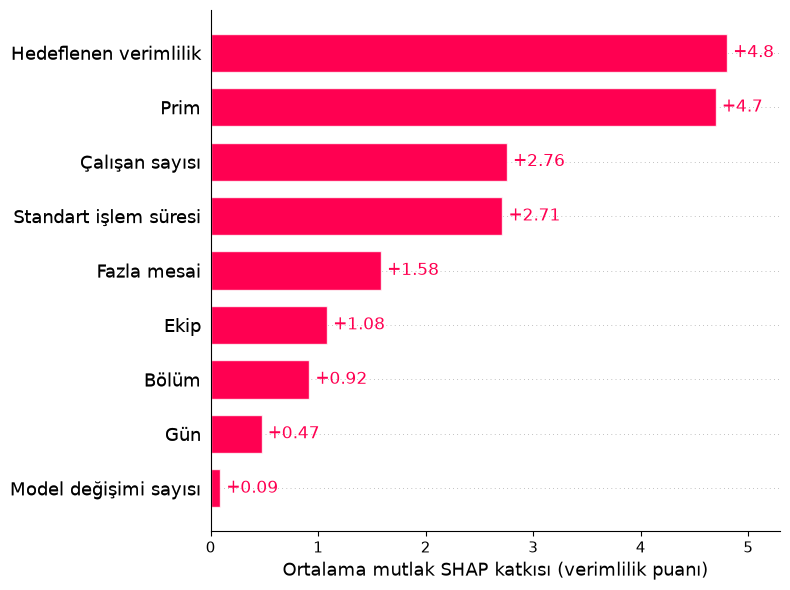

In [11]:
plt.figure()
shap.plots.bar(shap_values, show=False)
plt.gca().set_xlabel('Ortalama mutlak SHAP katkısı (verimlilik puanı)')
plt.tight_layout()
plt.show()

Çubuklar katkıların mutlak değerlerinin ortalamasını gösteriyor. Hedeflenen verimlilik ve prim ilk iki sırada.

Gerçek: 26.82 | Tahmin: 44.30


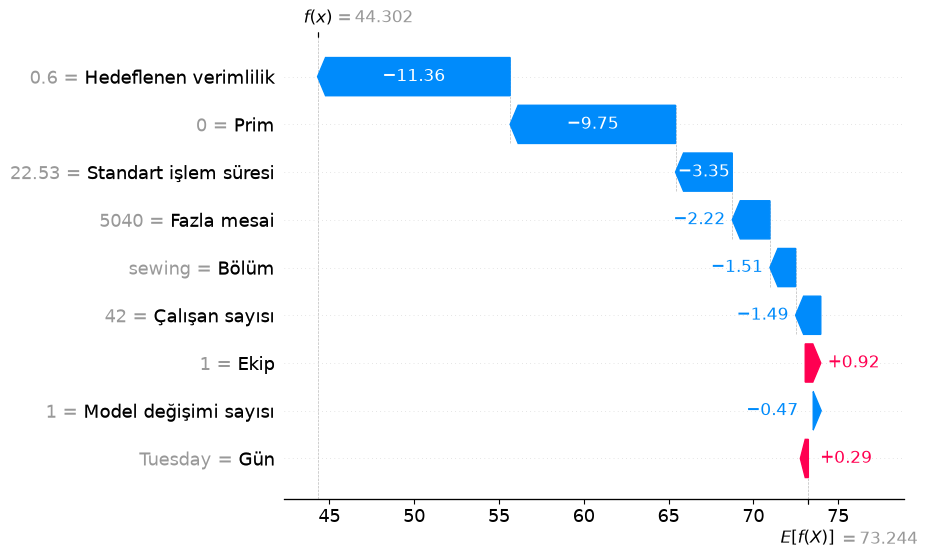

In [12]:
print(f"Gerçek: {example_actual:.2f} | Tahmin: {example_prediction:.2f}")
plt.figure()
shap.plots.waterfall(example_shap, show=False)
plt.show()

**24 Şubat 2015 tarihli dikim bölümü 1. ekip kaydı.** Tahmin, referans değere her girdinin katkısı eklenerek oluşturuldu. Bu kayıtta Hedeflenen verimlilik tahmini aşağı çekti; Prim tahmini aşağı çekti.

In [13]:
model_directory = Path("./models")
model_directory.mkdir(exist_ok=True)

model_artifact = {
    "model": best_model,
    "model_name": "Random Forest",
    "feature_columns": feature_columns,
    "test_mae": mean_absolute_error(y_test, y_pred) * 100,
    "test_rmse": root_mean_squared_error(y_test, y_pred) * 100,
    "test_r2": r2_score(y_test, y_pred),
}

model_path = model_directory / "garment_productivity_model.joblib"
joblib.dump(model_artifact, model_path)

print(f"Model kaydedildi: {model_path}")

Model kaydedildi: models\garment_productivity_model.joblib
